# Support vector machine (SVM)

This notebook trains the SVM on the 22 inputs saved by `features_pca.ipynb`. It tunes the SVM on the same five training folds, picks the decision threshold from training customers only, and then scores the 12,077 test customers once at the end. The test predictions are saved so they can be compared with the random forest and used in the McNemar test.

In [1]:
import os
import json
import time
import hashlib

# stops macOS printing "MallocStackLogging" messages from the parallel workers
os.environ.pop('MallocStackLogging', None)
os.environ.pop('MallocStackLoggingNoCompact', None)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import PredefinedSplit, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)
from pipeline import get_inputs_ready

RANDOM_STATE = 42
DATA_DIR = '../data'
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

NORMAL_COLOUR = '#2b5c8f'
THEFT_COLOUR = '#d95f02'

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

Before loading, `get_inputs_ready` (in `pipeline.py`) checks that all three files are in the data folder. If one is missing, it runs the notebook that makes it first, and that notebook's own inputs are checked the same way. So after a fresh clone, this notebook can be run on its own as long as `data/data.csv` is there.

In [2]:
# if a file this notebook reads is missing, run the notebook that makes it first
get_inputs_ready('svm_model.ipynb')

All inputs for svm_model.ipynb are in place.


## 1. Load the features and the split

`features.csv` has the 13 hand-made features and PC2 to PC10 for every customer, plus the train/test label and the fold number from the cleaning notebook. The checks below make sure it lines up with `split_info.csv`, so the SVM sees exactly the same training and test customers as the random forest.

In [3]:
data = pd.read_csv(os.path.join(DATA_DIR, 'features.csv'))
split_info = pd.read_csv(os.path.join(DATA_DIR, 'split_info.csv'))
with open(os.path.join(DATA_DIR, 'feature_info.json')) as f:
    feature_info = json.load(f)

model_inputs = feature_info['model_inputs']

assert len(data) == len(split_info), 'the two files have different numbers of customers'
assert (data['CONS_NO'].values == split_info['CONS_NO'].values).all(), 'customers are in a different order'
assert (data['FLAG'].values == split_info['FLAG'].values).all(), 'labels do not match'
assert (data['split'].values == split_info['split'].values).all(), 'train/test labels do not match'
assert not data[model_inputs].isna().any().any(), 'an input has empty values'

is_train = (data['split'] == 'train').to_numpy()
X_train = data.loc[is_train, model_inputs].to_numpy()
y_train = data.loc[is_train, 'FLAG'].to_numpy()
X_test = data.loc[~is_train, model_inputs].to_numpy()
y_test = data.loc[~is_train, 'FLAG'].to_numpy()
train_folds = data.loc[is_train, 'fold'].to_numpy()

print(f"Inputs ({len(model_inputs)}): {model_inputs}\n")
print(f"Training customers: {len(y_train):,} ({y_train.sum():,} thieves, {y_train.mean() * 100:.2f}%)")
print(f"Test customers:     {len(y_test):,} ({y_test.sum():,} thieves, {y_test.mean() * 100:.2f}%)")
print(f"Normal customers per thief in training: {(y_train == 0).sum() / y_train.sum():.2f}")

Inputs (22): ['mean_kwh', 'std_kwh', 'cv_kwh', 'zero_share', 'missing_share', 'longest_missing_run', 'trend_slope', 'trend_rel', 'n_sudden_drops', 'max_monthly_drop', 'weekend_share', 'dow_variation', 'weekly_autocorr', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10']

Training customers: 28,179 (2,505 thieves, 8.89%)
Test customers:     12,077 (1,074 thieves, 8.89%)
Normal customers per thief in training: 10.25


## 2. Set-up: scaling, class weights and folds

In [4]:
folds = PredefinedSplit(test_fold=train_folds)

SCALERS = ['standard', 'quantile']


def make_scaler(name):
    if name == 'standard':
        return StandardScaler()
    else:
        return QuantileTransformer(output_distribution='normal', random_state=RANDOM_STATE)


def make_svm_pipeline(scaler_name, model):
    return Pipeline([('scale', make_scaler(scaler_name)), ('svm', model)])


def cv_scores(model):
    scores = cross_validate(model, X_train, y_train, cv=folds, n_jobs=-1,
                            scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'})
    return scores['test_roc_auc'], scores['test_pr_auc']


print(f"Folds: {folds.get_n_splits()}")
for k in range(5):
    in_fold = (train_folds == k)
    print(f"  fold {k}: {in_fold.sum():,} customers, {y_train[in_fold].mean() * 100:.2f}% thieves")

Folds: 5
  fold 0: 5,636 customers, 8.89% thieves
  fold 1: 5,636 customers, 8.89% thieves
  fold 2: 5,636 customers, 8.89% thieves
  fold 3: 5,636 customers, 8.89% thieves
  fold 4: 5,635 customers, 8.89% thieves


In [5]:
LINEAR_C_GRID = [0.01, 0.1, 1.0]

linear_rows = []
linear_fold_scores = {}
for scaler_name in SCALERS:
    for C in LINEAR_C_GRID:
        model = make_svm_pipeline(scaler_name, LinearSVC(C=C, class_weight='balanced', max_iter=20000,
                                                          random_state=RANDOM_STATE))
        roc, pr = cv_scores(model)
        linear_fold_scores[(scaler_name, C)] = roc
        linear_rows.append({'scaler': scaler_name, 'C': C,
                            'ROC-AUC mean': roc.mean(), 'ROC-AUC sd': roc.std(),
                            'PR-AUC mean': pr.mean(), 'PR-AUC sd': pr.std()})

linear_results = pd.DataFrame(linear_rows)
best_linear = linear_results.loc[linear_results['ROC-AUC mean'].idxmax()]
print(f"Best linear SVM: {best_linear['scaler']} scaler, C = {best_linear['C']}, "
      f"ROC-AUC {best_linear['ROC-AUC mean']:.4f}, PR-AUC {best_linear['PR-AUC mean']:.4f}\n")
linear_results.round(4)

Best linear SVM: quantile scaler, C = 0.01, ROC-AUC 0.7511, PR-AUC 0.2649



,scaler,C,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd
0,standard,0.01,0.7474,0.0062,0.2552,0.0156
1,standard,0.10,0.7476,0.0062,0.2550,0.0155
2,standard,1.00,0.7476,0.0062,0.2549,0.0155
3,quantile,0.01,0.7511,0.0067,0.2649,0.0173
4,quantile,0.10,0.7511,0.0067,0.2645,0.0172
5,quantile,1.00,0.7511,0.0067,0.2644,0.0171


## 4. RBF kernel: tune C and gamma

The RBF kernel lets the boundary curve. It has a second setting, `gamma`, which says how far each training customer's influence reaches. A high `gamma` means each customer only affects its close neighbours, so the boundary can get wiggly and follow noise. A low `gamma` spreads the influence out and keeps the boundary smooth. `C` and `gamma` work against each other, so they are searched together.

The `gamma` values sit around scikit-learn's default (`'scale'`, which is 1 / 22 ≈ 0.045 here, because there are 22 scaled inputs): about a quarter of it, half of it, the default itself and roughly double. Each fit takes around 20 to 30 seconds on 22,500 customers, so the full grid (2 scalers × 4 C × 4 gamma × 5 folds = 160 fits) takes a while.

In [6]:
C_GRID = [0.1, 0.3, 1.0, 3.0]
GAMMA_GRID = [0.01, 0.02, 0.045, 0.1]

# The search is 160 SVM fits, which takes 20 to 45 minutes. So the results are saved to
# results/svm_grid_results.json the first time, and later runs load that file instead.
# Set RUN_GRID_SEARCH = True to force a fresh search.
RUN_GRID_SEARCH = False
RESULTS_DIR = '../results'
GRID_FILE = os.path.join(RESULTS_DIR, 'svm_grid_results.json')
os.makedirs(RESULTS_DIR, exist_ok=True)

# A fingerprint of the exact training data: the inputs, the labels and the folds. If any single
# number changes (even a feature calculated a bit differently), the fingerprint changes too.
fingerprint = hashlib.sha256()
fingerprint.update(np.ascontiguousarray(X_train, dtype=np.float64).tobytes())
fingerprint.update(np.ascontiguousarray(y_train, dtype=np.int64).tobytes())
fingerprint.update(np.ascontiguousarray(train_folds, dtype=np.int64).tobytes())
data_fingerprint = fingerprint.hexdigest()

saved = None
if os.path.exists(GRID_FILE) and not RUN_GRID_SEARCH:
    with open(GRID_FILE) as f:
        saved = json.load(f)
    # the saved results only count if they came from the same data and the same grid
    same_setup = True
    if saved['inputs'] != model_inputs:
        same_setup = False
    if saved['scalers'] != SCALERS or saved['C_grid'] != C_GRID or saved['gamma_grid'] != GAMMA_GRID:
        same_setup = False
    if saved.get('data_fingerprint') != data_fingerprint:
        same_setup = False
    if not same_setup:
        print("The data or the grid has changed since the results were saved, so the search runs again.")
        saved = None

if saved is not None:
    rbf_rows = saved['rows']
    rbf_fold_scores = {}
    for item in saved['fold_scores']:
        key = (item['scaler'], item['C'], item['gamma'])
        rbf_fold_scores[key] = np.array(item['roc_auc_per_fold'])
    print(f"Loaded the grid results from {GRID_FILE} (saved on {saved['saved_on']}).")
    print("Set RUN_GRID_SEARCH = True to run the search again.")
else:
    rbf_rows = []
    rbf_fold_scores = {}
    start = time.time()
    for scaler_name in SCALERS:
        for C in C_GRID:
            for gamma in GAMMA_GRID:
                model = make_svm_pipeline(scaler_name, SVC(kernel='rbf', C=C, gamma=gamma,
                                                           class_weight='balanced', cache_size=1000))
                roc, pr = cv_scores(model)
                rbf_fold_scores[(scaler_name, C, gamma)] = roc
                rbf_rows.append({'scaler': scaler_name, 'C': C, 'gamma': gamma,
                                 'ROC-AUC mean': float(roc.mean()), 'ROC-AUC sd': float(roc.std()),
                                 'PR-AUC mean': float(pr.mean()), 'PR-AUC sd': float(pr.std())})
        print(f"done: {scaler_name} scaler ({(time.time() - start) / 60:.1f} min so far)")

    fold_list = []
    for key in rbf_fold_scores:
        fold_list.append({'scaler': key[0], 'C': key[1], 'gamma': key[2],
                          'roc_auc_per_fold': rbf_fold_scores[key].tolist()})
    to_save = {
        'saved_on': time.strftime('%Y-%m-%d %H:%M'),
        'inputs': model_inputs,
        'scalers': SCALERS,
        'C_grid': C_GRID,
        'gamma_grid': GAMMA_GRID,
        'data_fingerprint': data_fingerprint,
        'rows': rbf_rows,
        'fold_scores': fold_list,
    }
    with open(GRID_FILE, 'w') as f:
        json.dump(to_save, f, indent=1)
    print(f"Saved the grid results to {GRID_FILE}")

rbf_results = pd.DataFrame(rbf_rows)
rbf_results.sort_values('ROC-AUC mean', ascending=False).head(8).round(4)

Loaded the grid results from ../results/svm_grid_results.json (saved on 2026-10-15 01:11).
Set RUN_GRID_SEARCH = True to run the search again.


,scaler,C,gamma,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd
6,standard,0.3,0.045,0.7888,0.0036,0.3291,0.0100
28,quantile,3.0,0.010,0.7857,0.0061,0.3309,0.0146
9,standard,1.0,0.020,0.7856,0.0054,0.3323,0.0112
25,quantile,1.0,0.020,0.7851,0.0057,0.3343,0.0157
7,standard,0.3,0.100,0.7838,0.0036,0.3186,0.0121
24,quantile,1.0,0.010,0.7835,0.0061,0.3268,0.0180
22,quantile,0.3,0.045,0.7829,0.0064,0.3295,0.0159
21,quantile,0.3,0.020,0.7826,0.0066,0.3298,0.0205


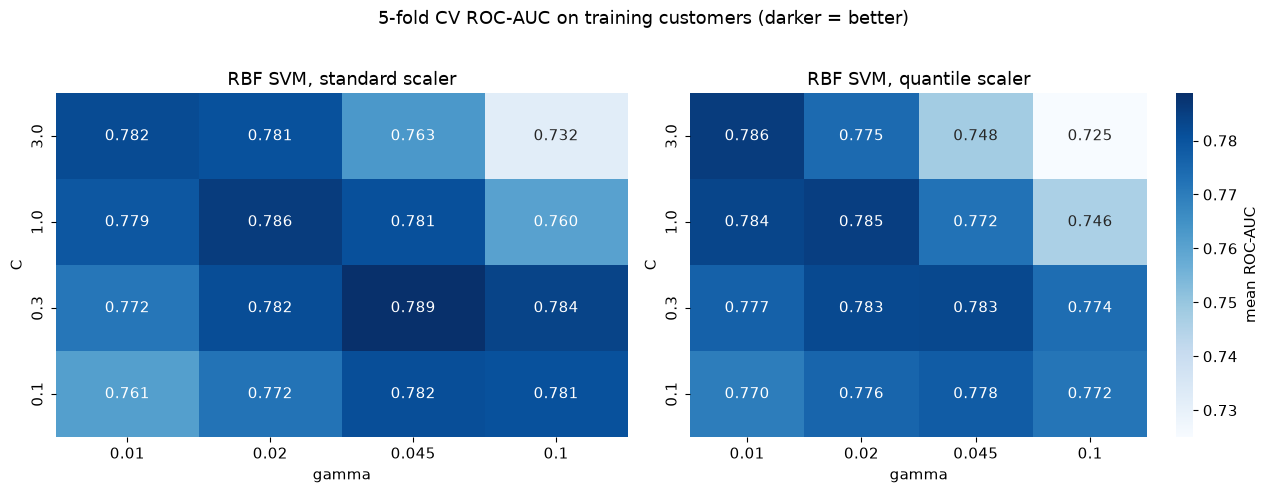

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
low = rbf_results['ROC-AUC mean'].min()
high = rbf_results['ROC-AUC mean'].max()
for i in range(len(SCALERS)):
    scaler_name = SCALERS[i]
    part = rbf_results[rbf_results['scaler'] == scaler_name]
    grid = part.pivot(index='C', columns='gamma', values='ROC-AUC mean')
    sns.heatmap(grid, annot=True, fmt='.3f', cmap='Blues', vmin=low, vmax=high, ax=axes[i],
                cbar=(i == 1), cbar_kws={'label': 'mean ROC-AUC'})
    axes[i].invert_yaxis()
    axes[i].set_title(f'RBF SVM, {scaler_name} scaler')
    axes[i].set_xlabel('gamma')
    axes[i].set_ylabel('C')
plt.suptitle('5-fold CV ROC-AUC on training customers (darker = better)', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step6_svm_tuning_grid.png'), dpi=200, bbox_inches='tight')
plt.show()

Differences in the third decimal place are within the fold-to-fold wobble, so the rule for picking the settings is: take every setting whose mean ROC-AUC is within one fold standard deviation of the best, and from those keep the one with the highest PR-AUC. PR-AUC is the better guide when only 9% of customers are thieves, because it looks at how many of the flagged customers really are thieves.

In [8]:
best_row = rbf_results.loc[rbf_results['ROC-AUC mean'].idxmax()]
wobble = best_row['ROC-AUC sd']
close_enough = rbf_results[rbf_results['ROC-AUC mean'] >= best_row['ROC-AUC mean'] - wobble]
chosen = close_enough.loc[close_enough['PR-AUC mean'].idxmax()]

best_scaler = chosen['scaler']
best_C = float(chosen['C'])
best_gamma = float(chosen['gamma'])
best_key = (best_scaler, best_C, best_gamma)

print(f"Highest ROC-AUC: {best_row['scaler']} scaler, C = {best_row['C']}, gamma = {best_row['gamma']}: "
      f"{best_row['ROC-AUC mean']:.4f} (fold sd {wobble:.4f})")
print(f"Settings within one fold sd of it: {len(close_enough)}")
print(f"Chosen (highest PR-AUC among those): {best_scaler} scaler, C = {best_C}, gamma = {best_gamma}")
print(f"  ROC-AUC {chosen['ROC-AUC mean']:.4f} (sd {chosen['ROC-AUC sd']:.4f}), "
      f"PR-AUC {chosen['PR-AUC mean']:.4f} (sd {chosen['PR-AUC sd']:.4f})")
print(f"  per fold ROC-AUC: {np.round(rbf_fold_scores[best_key], 4)}")

# is the chosen point on the edge of the grid? if so the best value might be outside it
edge_notes = []
if best_C == min(C_GRID) or best_C == max(C_GRID):
    edge_notes.append('C')
if best_gamma == min(GAMMA_GRID) or best_gamma == max(GAMMA_GRID):
    edge_notes.append('gamma')
if len(edge_notes) == 0:
    print("\nThe chosen point is inside the grid on both settings, so the grid covers the best region.")
else:
    print(f"\nThe chosen point is on the edge of the grid for: {edge_notes}")

close_enough.sort_values('PR-AUC mean', ascending=False).round(4)

Highest ROC-AUC: standard scaler, C = 0.3, gamma = 0.045: 0.7888 (fold sd 0.0036)
Settings within one fold sd of it: 3
Chosen (highest PR-AUC among those): standard scaler, C = 1.0, gamma = 0.02
  ROC-AUC 0.7856 (sd 0.0054), PR-AUC 0.3323 (sd 0.0112)
  per fold ROC-AUC: [0.7899 0.7905 0.7761 0.7831 0.7882]

The chosen point is inside the grid on both settings, so the grid covers the best region.


,scaler,C,gamma,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd
9,standard,1.0,0.020,0.7856,0.0054,0.3323,0.0112
28,quantile,3.0,0.010,0.7857,0.0061,0.3309,0.0146
6,standard,0.3,0.045,0.7888,0.0036,0.3291,0.0100


## 5. Linear or RBF?

If the curved boundary only wins on average, it might be luck in one or two folds. So the gain is checked fold by fold.

In [9]:
linear_key = (best_linear['scaler'], best_linear['C'])
gain = rbf_fold_scores[best_key] - linear_fold_scores[linear_key]

print(f"Linear SVM ({linear_key[0]}, C = {linear_key[1]}):  ROC-AUC {linear_fold_scores[linear_key].mean():.4f}")
print(f"RBF SVM ({best_scaler}, C = {best_C}, gamma = {best_gamma}): ROC-AUC {rbf_fold_scores[best_key].mean():.4f}")
print(f"RBF gain per fold: {np.round(gain, 4)}  (better in {(gain > 0).sum()} of 5 folds)")

Linear SVM (quantile, C = 0.01):  ROC-AUC 0.7511
RBF SVM (standard, C = 1.0, gamma = 0.02): ROC-AUC 0.7856
RBF gain per fold: [0.0421 0.0338 0.0276 0.0225 0.0465]  (better in 5 of 5 folds)


## 6. Pick the decision threshold

The SVM gives every customer a score: how far they sit from the boundary, positive on the theft side. The usual cut is 0. With balanced class weights that cut catches many thieves but also flags a lot of normal customers, which hurts accuracy.

The cut is picked from training customers only. `cross_val_predict` gives every training customer a score from the model that did not see them in training (out-of-fold scores). The cut with the best F1 score for the theft class is then chosen. F1 balances two things: how many of the flagged customers are really thieves (precision) and how many of the thieves get flagged (recall). The test set is not touched here.

In [10]:
chosen_model = make_svm_pipeline(best_scaler, SVC(kernel='rbf', C=best_C, gamma=best_gamma,
                                                  class_weight='balanced', cache_size=1000))
oof_scores = cross_val_predict(chosen_model, X_train, y_train, cv=folds, n_jobs=-1,
                               method='decision_function')

precision, recall, cuts = precision_recall_curve(y_train, oof_scores)
precision = precision[:-1]       # the last point has no cut attached to it
recall = recall[:-1]
both = precision + recall
f1_values = np.where(both > 0, 2 * precision * recall / np.where(both > 0, both, 1.0), 0.0)
best_cut = float(cuts[np.argmax(f1_values)])


def metrics_at(y_true, scores, cut):
    pred = (scores >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'cut': cut,
        'accuracy': accuracy_score(y_true, pred),
        'balanced accuracy': balanced_accuracy_score(y_true, pred),
        'precision (theft)': precision_score(y_true, pred, zero_division=0),
        'recall (theft)': recall_score(y_true, pred, zero_division=0),
        'F1 (theft)': f1_score(y_true, pred, zero_division=0),
        'flagged %': pred.mean() * 100,
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }


cut_table = pd.DataFrame([metrics_at(y_train, oof_scores, 0.0), metrics_at(y_train, oof_scores, best_cut)],
                         index=['default cut (0)', 'best-F1 cut'])
print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_train, oof_scores):.4f}, "
      f"PR-AUC: {average_precision_score(y_train, oof_scores):.4f}")
print(f"Accuracy if every training customer is called normal: {(y_train == 0).mean():.4f}\n")
cut_table.round(4)

Out-of-fold ROC-AUC: 0.7854, PR-AUC: 0.3315
Accuracy if every training customer is called normal: 0.9111



,cut,accuracy,balanced accuracy,precision (theft),recall (theft),F1 (theft),flagged %,TP,FP,FN,TN
default cut (0),0.0000,0.7855,0.7086,0.2327,0.6152,0.3377,23.4998,1541,5081,964,20593
best-F1 cut,0.5152,0.8691,0.6821,0.3291,0.4547,0.3818,12.2822,1139,2322,1366,23352


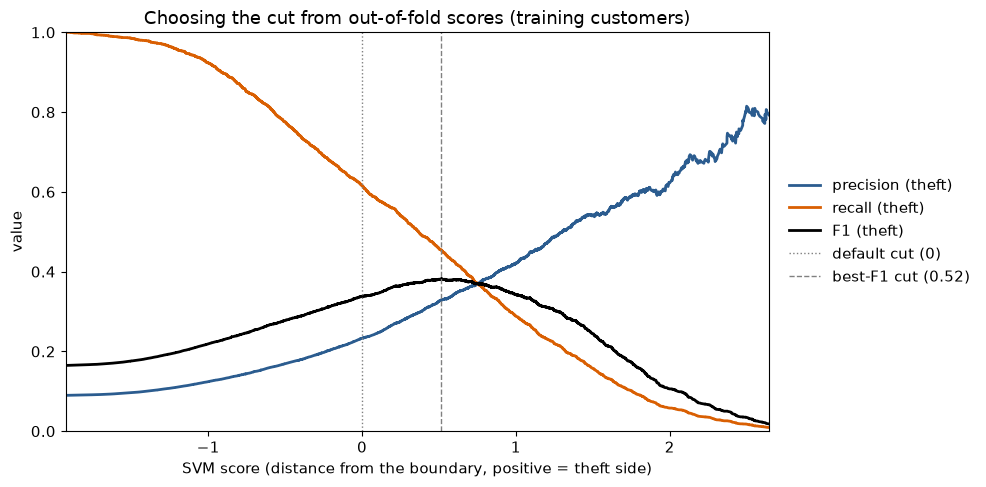

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(cuts, precision, color=NORMAL_COLOUR, linewidth=2, label='precision (theft)')
plt.plot(cuts, recall, color=THEFT_COLOUR, linewidth=2, label='recall (theft)')
plt.plot(cuts, f1_values, color='black', linewidth=2, label='F1 (theft)')
plt.axvline(0, color='grey', linestyle=':', linewidth=1, label='default cut (0)')
plt.axvline(best_cut, color='grey', linestyle='--', linewidth=1, label=f'best-F1 cut ({best_cut:.2f})')
plt.xlim(np.percentile(oof_scores, 1), np.percentile(oof_scores, 99.9))
plt.ylim(0, 1)
plt.xlabel('SVM score (distance from the boundary, positive = theft side)')
plt.ylabel('value')
plt.title('Choosing the cut from out-of-fold scores (training customers)')
plt.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step6_svm_threshold.png'), dpi=200, bbox_inches='tight')
plt.show()

## 7. Final model and the test set

The chosen SVM is now trained on all 28,179 training customers and scores the 12,077 test customers. This is the only time the test set is used. Accuracy is reported because the assignment compares the two models on it, but it has to be read next to the baseline: calling every customer normal already gets about 91%.

In [12]:
start = time.time()
final_model = make_svm_pipeline(best_scaler, SVC(kernel='rbf', C=best_C, gamma=best_gamma,
                                                 class_weight='balanced', cache_size=1000))
final_model.fit(X_train, y_train)
fit_minutes = (time.time() - start) / 60

svm_part = final_model.named_steps['svm']
n_support = svm_part.n_support_
print(f"Training took {fit_minutes:.1f} min")
print(f"Support vectors: {n_support.sum():,} of {len(y_train):,} training customers "
      f"({n_support.sum() / len(y_train) * 100:.1f}%)")
print(f"  normal: {n_support[0]:,} of {(y_train == 0).sum():,} ({n_support[0] / (y_train == 0).sum() * 100:.1f}%)")
print(f"  theft:  {n_support[1]:,} of {y_train.sum():,} ({n_support[1] / y_train.sum() * 100:.1f}%)")

test_scores = final_model.decision_function(X_test)
test_roc = roc_auc_score(y_test, test_scores)
test_pr = average_precision_score(y_test, test_scores)
baseline_accuracy = (y_test == 0).mean()

test_table = pd.DataFrame([metrics_at(y_test, test_scores, 0.0), metrics_at(y_test, test_scores, best_cut)],
                          index=['default cut (0)', f'best-F1 cut ({best_cut:.3f})'])
print(f"\nTest ROC-AUC: {test_roc:.4f}  (CV mean was {rbf_fold_scores[best_key].mean():.4f})")
print(f"Test PR-AUC:  {test_pr:.4f}  (CV mean was {chosen['PR-AUC mean']:.4f})")
print(f"Test accuracy if every customer is called normal: {baseline_accuracy:.4f}\n")
test_table.round(4)

Training took 0.3 min
Support vectors: 17,968 of 28,179 training customers (63.8%)
  normal: 16,220 of 25,674 (63.2%)
  theft:  1,748 of 2,505 (69.8%)

Test ROC-AUC: 0.7857  (CV mean was 0.7856)
Test PR-AUC:  0.3405  (CV mean was 0.3323)
Test accuracy if every customer is called normal: 0.9111



,cut,accuracy,balanced accuracy,precision (theft),recall (theft),F1 (theft),flagged %,TP,FP,FN,TN
default cut (0),0.0000,0.7909,0.7139,0.2393,0.6201,0.3453,23.0438,666,2117,408,8886
best-F1 cut (0.515),0.5152,0.8664,0.6826,0.3233,0.4590,0.3794,12.6273,493,1032,581,9971


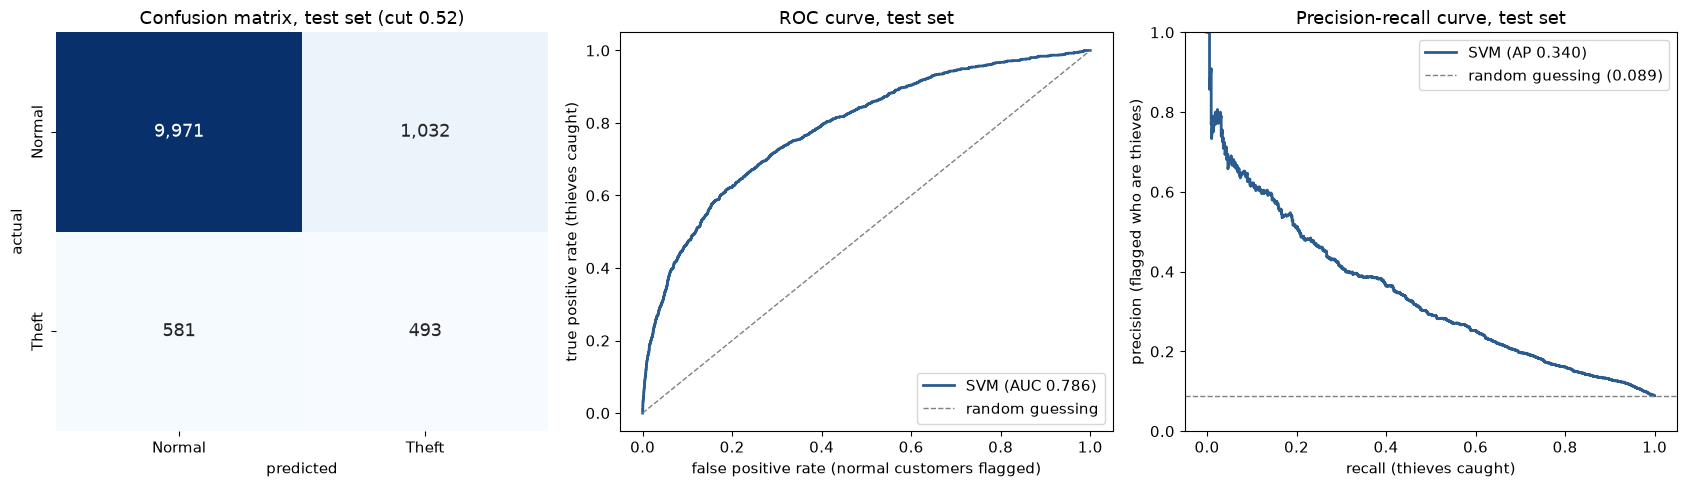

In [13]:
test_pred = (test_scores >= best_cut).astype(int)
matrix = confusion_matrix(y_test, test_pred, labels=[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.heatmap(matrix, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Normal', 'Theft'], yticklabels=['Normal', 'Theft'], annot_kws={'size': 13})
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('actual')
axes[0].set_title(f'Confusion matrix, test set (cut {best_cut:.2f})')

fpr, tpr, _ = roc_curve(y_test, test_scores)
axes[1].plot(fpr, tpr, color=NORMAL_COLOUR, linewidth=2, label=f'SVM (AUC {test_roc:.3f})')
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=1, label='random guessing')
axes[1].set_xlabel('false positive rate (normal customers flagged)')
axes[1].set_ylabel('true positive rate (thieves caught)')
axes[1].set_title('ROC curve, test set')
axes[1].legend(loc='lower right')

test_precision, test_recall, _ = precision_recall_curve(y_test, test_scores)
axes[2].plot(test_recall, test_precision, color=NORMAL_COLOUR, linewidth=2, label=f'SVM (AP {test_pr:.3f})')
axes[2].axhline(y_test.mean(), color='grey', linestyle='--', linewidth=1,
                label=f'random guessing ({y_test.mean():.3f})')
axes[2].set_xlabel('recall (thieves caught)')
axes[2].set_ylabel('precision (flagged who are thieves)')
axes[2].set_title('Precision-recall curve, test set')
axes[2].set_ylim(0, 1)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step6_svm_test_results.png'), dpi=200, bbox_inches='tight')
plt.show()

## 8. Save the predictions

The test scores and predictions go into `svm_test_predictions.csv`, one row per test customer with `CONS_NO`, so the McNemar test can pair them with the random forest's predictions customer by customer. The chosen settings and all the numbers above go into `svm_info.json` for the report.

In [14]:
predictions = pd.DataFrame({
    'CONS_NO': data.loc[~is_train, 'CONS_NO'].to_numpy(),
    'FLAG': y_test,
    'svm_score': test_scores,
    'svm_pred': test_pred,
})
predictions.to_csv(os.path.join(DATA_DIR, 'svm_test_predictions.csv'), index=False)


def plain_numbers(row):
    # numpy numbers can't go into json directly, so turn them into normal floats
    out = {}
    for key in row:
        out[key] = float(row[key])
    return out


per_fold = []
for value in rbf_fold_scores[best_key]:
    per_fold.append(float(value))

svm_info = {
    'inputs': model_inputs,
    'kernel': 'rbf',
    'scaler': best_scaler,
    'C': best_C,
    'gamma': best_gamma,
    'class_weight': 'balanced',
    'cut': best_cut,
    'cut_rule': 'best F1 for the theft class on out-of-fold scores of the training customers',
    'cv_roc_auc_mean': float(rbf_fold_scores[best_key].mean()),
    'cv_roc_auc_per_fold': per_fold,
    'cv_pr_auc_mean': float(chosen['PR-AUC mean']),
    'best_linear_svm': {'scaler': best_linear['scaler'], 'C': float(best_linear['C']),
                        'cv_roc_auc_mean': float(best_linear['ROC-AUC mean']),
                        'cv_pr_auc_mean': float(best_linear['PR-AUC mean'])},
    'support_vectors': int(n_support.sum()),
    'test_roc_auc': float(test_roc),
    'test_pr_auc': float(test_pr),
    'test_baseline_accuracy_all_normal': float(baseline_accuracy),
    'test_at_cut': plain_numbers(metrics_at(y_test, test_scores, best_cut)),
    'test_at_zero': plain_numbers(metrics_at(y_test, test_scores, 0.0)),
}
with open(os.path.join(DATA_DIR, 'svm_info.json'), 'w') as f:
    json.dump(svm_info, f, indent=2)

print(f"Saved svm_test_predictions.csv: {len(predictions):,} test customers")
print("Saved svm_info.json")
predictions.head()

Saved svm_test_predictions.csv: 12,077 test customers
Saved svm_info.json


,CONS_NO,FLAG,svm_score,svm_pred
0,0387DD8A07E07FDA6271170F86AD9151,1,0.074537,0
1,4B75AC4F2D8434CFF62DB64D0BB43103,1,1.034779,1
2,C7952FEE130E744EC8CAA7490F72D3F4,1,-0.546761,0
3,E34D1B467A365835A4A8AAD9395D49AA,1,-0.602178,0
4,441D4A577AAD02F6C003644640C2619C,1,-1.247030,0
